# 07 · Comparing model types
Logistic regression is the **baseline**. Every other model gets exactly the same input and data as the improved probe from notebook 06:
- **input:** the last-answer-token hidden state averaged over layers 18–36. The layer-weighting nets instead see the 19 layers stacked, and learn how to weight them.
- **training:** clear-cut labels only (margin ≥ 0.05).

Models (`src/model_compare.py`):

| Family | Models |
|---|---|
| linear | logistic regression (baseline), L1 logistic regression, linear SVM |
| kernel | RBF-kernel SVM |
| instance | k-nearest neighbours (cosine) |
| probabilistic | Gaussian naive Bayes on 32 PCA components |
| trees | random forest, gradient boosting on 64 PCA components |
| neural | MLP with one hidden layer; learned layer weights + linear head; learned layer weights + MLP head |

**Protocol:** same as notebook 06. Each model's small grid is scored by grouped 5-fold CV on train+val, repeated 3 times, and the best setting by CV is kept. Then every model is fit on all of train+val and scored on test once. Ranking is by CV; the test column is a check, not a selection step.

Needs the feature files from notebooks 05 and 06.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
%load_ext autoreload
%autoreload 2
from src import config

In [2]:
import time, warnings, numpy as np, pandas as pd
from src.io_utils import read_jsonl
from src.improve import load_probe_data, layer_average, cv_auroc, test_auroc, paired_bootstrap
from src.model_compare import model_zoo, sk_model

warnings.filterwarnings('ignore', category=UserWarning)   # liblinear / sklearn chatter
LATE, MARGIN = range(18, 37), 0.05
d = load_probe_data(read_jsonl(config.ALL_LAYERS_DATASET_PATH))
X = {'avg': layer_average(d.answer_last, LATE), 'stack': d.answer_last[:, list(LATE)]}
feature = lambda kind: (lambda i: X[kind][i])
zoo = model_zoo()
{k: v.shape for k, v in X.items()}

/Users/snehvora/Desktop/Projects/Research/hallucination-research/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'avg': (500, 2048), 'stack': (500, 19, 2048)}

## Cross-validation (every grid setting)

In [3]:
grid_rows = []
for name, spec in zoo.items():
    for label, make in spec['grid'].items():
        t = time.time()
        r = cv_auroc(d, sk_model(d, feature(spec['input']), make, min_margin=MARGIN))
        grid_rows.append({'model': name, 'family': spec['family'], 'setting': label, **r, 'seconds': time.time() - t})
grid = pd.DataFrame(grid_rows)
best = grid.loc[grid.groupby('model', sort=False)['cv_auroc'].idxmax()].reset_index(drop=True)
grid.round(3)

,model,family,setting,cv_auroc,cv_std,seconds
0,Logistic regression (baseline),linear,C=0.0001,0.685,0.002,0.228
1,Logistic regression (baseline),linear,C=0.001,0.707,0.004,0.231
2,Logistic regression (baseline),linear,C=0.01,0.709,0.008,0.258
3,"Logistic regression, L1 (sparse)",linear,C=0.1,0.680,0.013,0.333
4,"Logistic regression, L1 (sparse)",linear,C=0.3,0.670,0.017,0.345
5,"Logistic regression, L1 (sparse)",linear,C=1.0,0.664,0.009,0.387
6,Linear SVM,linear,C=1e-05,0.597,0.042,0.489
7,Linear SVM,linear,C=0.0001,0.686,0.002,0.486
8,Linear SVM,linear,C=0.001,0.711,0.008,0.450
9,RBF-kernel SVM,kernel,C=0.3,0.647,0.006,0.579


## Does the clear-cut-label filter help every model?
Each model's best setting retrained on **all** labels.

In [4]:
all_labels = []
for _, row in best.iterrows():
    spec = zoo[row['model']]
    r = cv_auroc(d, sk_model(d, feature(spec['input']), spec['grid'][row['setting']], min_margin=0.0))
    all_labels.append(r['cv_auroc'])
best['cv_auroc_all_labels'] = all_labels

## Test (once per model, at its CV-chosen setting)

In [5]:
tests, probs = [], {}
for _, row in best.iterrows():
    spec = zoo[row['model']]
    t = test_auroc(d, sk_model(d, feature(spec['input']), spec['grid'][row['setting']], min_margin=MARGIN))
    probs[row['model']] = t['probs']
    tests.append({'test_auroc': t['test_auroc'], 'test_ci95': np.round(t['ci95'], 3).tolist()})
best = pd.concat([best, pd.DataFrame(tests)], axis=1)

y_test = d.y[d.test]
base_name = 'Logistic regression (baseline)'
base_cv = best.loc[best['model'] == base_name, 'cv_auroc'].item()
vs = [paired_bootstrap(y_test, probs[base_name], probs[m]) for m in best['model']]
best['cv_vs_baseline'] = best['cv_auroc'] - base_cv
best['test_vs_baseline'] = [v['diff'] for v in vs]
best['test_diff_ci95'] = [np.round(v['ci95'], 3).tolist() for v in vs]
best['P(better than baseline)'] = [v['p_b_better'] for v in vs]
table = best.sort_values('cv_auroc', ascending=False)[
    ['model', 'family', 'setting', 'cv_auroc', 'cv_std', 'cv_auroc_all_labels', 'test_auroc', 'test_ci95',
     'cv_vs_baseline', 'test_vs_baseline', 'test_diff_ci95', 'P(better than baseline)', 'seconds']]
table.round(3)

,model,family,setting,cv_auroc,cv_std,cv_auroc_all_labels,test_auroc,test_ci95,cv_vs_baseline,test_vs_baseline,test_diff_ci95,P(better than baseline),seconds
2,Linear SVM,linear,C=0.001,0.711,0.008,0.700,0.695,"[0.56, 0.811]",0.003,-0.023,"[-0.06, 0.015]",0.108,0.450
8,"Neural net: MLP, 1 hidden layer",neural,"h=256,epochs=150",0.709,0.003,0.690,0.749,"[0.628, 0.851]",0.001,0.032,"[-0.032, 0.11]",0.825,43.447
0,Logistic regression (baseline),linear,C=0.01,0.709,0.008,0.684,0.717,"[0.588, 0.833]",0.000,0.000,"[0.0, 0.0]",0.000,0.258
9,Neural net: learned layer weights + linear,neural,epochs=200,0.708,0.006,0.687,0.714,"[0.582, 0.83]",-0.001,-0.003,"[-0.034, 0.031]",0.406,95.572
3,RBF-kernel SVM,kernel,C=3.0,0.701,0.003,0.689,0.761,"[0.643, 0.865]",-0.008,0.044,"[-0.017, 0.112]",0.921,0.583
10,Neural net: learned layer weights + MLP,neural,"h=64,epochs=100",0.700,0.002,0.684,0.725,"[0.595, 0.837]",-0.009,0.008,"[-0.048, 0.064]",0.622,57.411
6,Random forest,trees,max_features=0.1,0.696,0.001,0.681,0.741,"[0.614, 0.849]",-0.013,0.023,"[-0.066, 0.114]",0.692,10.470
1,"Logistic regression, L1 (sparse)",linear,C=0.1,0.680,0.013,0.636,0.662,"[0.526, 0.784]",-0.029,-0.055,"[-0.132, 0.018]",0.076,0.333
4,k-nearest neighbours,instance,k=31,0.661,0.005,0.649,0.720,"[0.592, 0.833]",-0.047,0.003,"[-0.096, 0.102]",0.524,0.192
7,Gradient boosting (PCA 64),trees,lr=0.03,0.654,0.012,0.640,0.724,"[0.601, 0.831]",-0.054,0.007,"[-0.112, 0.131]",0.556,4.806


## What the layer-weighting net learned
With a softmax over layers it can put its weight anywhere in 18–36. Where it ends up is a check on the layer sweep from notebook 05.

In [6]:
from src.model_compare import LayerWeightedNet
spec = zoo['Neural net: learned layer weights + linear']
row = best[best['model'] == 'Neural net: learned layer weights + linear'].iloc[0]
tr = d.pool[d.label_margin[d.pool] >= MARGIN]
net = spec['grid'][row['setting']]().fit(X['stack'][tr], d.y[tr])
weights = pd.Series(net.layer_weights(), index=[f'L{L}' for L in LATE])
weights.round(3).to_frame('weight').T

,L18,L19,L20,L21,L22,L23,L24,L25,L26,L27,L28,L29,L30,L31,L32,L33,L34,L35,L36
weight,0.0,0.0,0.0,0.0,0.002,0.0,0.0,0.0,0.0,0.0,0.001,0.231,0.004,0.001,0.061,0.62,0.012,0.043,0.022


## Save

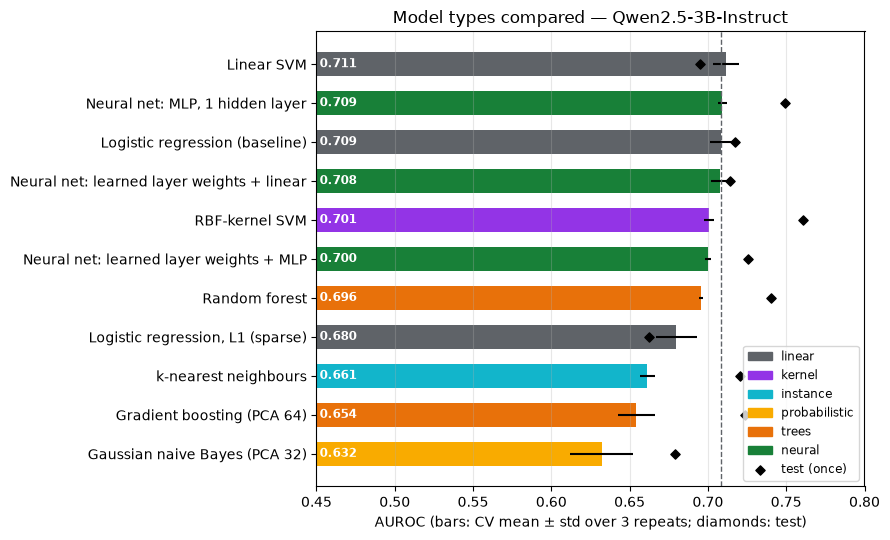

In [7]:
import json
import matplotlib.pyplot as plt

tag = f"{config.MODEL_NAME.split('/')[-1]}_answer_last_token_L18-36avg"
config.RESULTS_DIR.mkdir(exist_ok=True)
grid.to_csv(config.RESULTS_DIR / f'model_comparison_grid_{tag}.csv', index=False)
table.to_csv(config.RESULTS_DIR / f'model_comparison_{tag}.csv', index=False)
(config.RESULTS_DIR / f'model_comparison_{tag}.json').write_text(json.dumps({
    'model_name': config.MODEL_NAME, 'input': 'answer_last_token, mean over layers 18-36 (stacked for layer-weighting nets)',
    'min_label_margin': MARGIN, 'baseline': base_name,
    'protocol': '5-fold CV on train+val grouped by question, repeated 3x; best grid setting by CV; test once per model',
    'models': table.to_dict(orient='records'), 'learned_layer_weights': weights.to_dict()}, indent=2, default=float))

colors = {'linear': '#5f6368', 'kernel': '#9334e6', 'instance': '#12b5cb', 'probabilistic': '#f9ab00',
          'trees': '#e8710a', 'neural': '#188038'}
t = table.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(t['model'], t['cv_auroc'], xerr=t['cv_std'], color=[colors[f] for f in t['family']], height=0.62)
ax.scatter(t['test_auroc'], t['model'], color='black', marker='D', s=22, zorder=3, label='test (once)')
ax.axvline(base_cv, color='#5f6368', ls='--', lw=1)
for y, (v, sd) in enumerate(zip(t['cv_auroc'], t['cv_std'])):
    ax.text(0.452, y, f'{v:.3f}', va='center', fontsize=8.5, color='white', fontweight='bold')
ax.set_xlim(0.45, 0.8); ax.set_xlabel('AUROC (bars: CV mean ± std over 3 repeats; diamonds: test)')
ax.set_title(f"Model types compared — {config.MODEL_NAME.split('/')[-1]}")
from matplotlib.patches import Patch
handles = [Patch(color=c, label=f) for f, c in colors.items()] + [ax.collections[-1]]
ax.grid(axis='x', alpha=0.3); ax.legend(handles=handles, loc='lower right', fontsize=8.5)
fig.tight_layout()
fig.savefig(config.RESULTS_DIR / f'model_comparison_{tag}.png', dpi=150)
plt.show()

## Reading the results
See the summary table above. The main pattern: on ~250 training examples with 2,048 features, the linear models, the RBF SVM, the random forest and the small neural nets all land within a few hundredths of each other. That's well inside the noise of a 75-question test set. The extra capacity of a neural net has nothing more to learn from this little (and noisily labelled) data, so the simplest model is as good as any. Models that throw away information (L1 sparsity, k-NN, naive Bayes on PCA, boosting on PCA) do worse.